In [336]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%load_ext autoreload
%autoreload 2

from model_config import (
    split_by_group,
    compare_feature_sets,
    make_ridge_model,
    calculate_metrics
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Data Preperation

## 1.1. Preprocessing pipeline

Individual measurement files are loaded and combined into single dataframe. Source filenames and row numbers are retained for traceability, and specimen identifier from each filename.

In [337]:
def load_data(data_dir='data'):
    """Load measurement Excel files and add source and specimen identifiers.

    Parameters
    ----------
    data_dir : str or pathlib.Path, default "data"
        Directory containing the measurement .xlsx files.

    Returns
    -------
    pandas.DataFrame
        Combined measurements with source_filename, source_row, and
        specimen_id columns.
    """
    files = sorted(Path(data_dir).glob('*.xlsx'))
    dfs = []

    for file in files:
        quartz_df = pd.read_excel(file)
        quartz_df['source_filename'] = file.name
        quartz_df['source_row'] = range(1, len(quartz_df) + 1)

        dfs.append(quartz_df)

    measurements = pd.concat(dfs, ignore_index=True)
    
    measurements["specimen_id"] = measurements["source_filename"].str.extract(
        r"sample_(S\d+)",
        expand=False
    )

    return measurements


measurements = load_data()

Each measurement is clasified as either standard or high-temperature based on source file.

In [338]:
def measurement_regime(df: pd.DataFrame) -> pd.DataFrame:
    """Add a measurement regime based on the source filename.

    Parameters
    ----------
    df : pandas.DataFrame
        Measurements containing a source_filename column.

    Returns
    -------
    pandas.DataFrame
        A copy with a measurement regime column. Filenames containing
        "high temperature", ignoring case, are classified as "high temperature";
        all others are classified as "standard".
    """
    result = df.copy()
    result['measurement regime'] = result['source_filename'].apply(
        lambda x: 'high temperature' if 'high temperature' in x.lower() else 'standard')
    return result

Specimen level data is loaded seperatley from measurement data. Table contains information descriving the prep and physical properties of each specimen.

In [339]:
def load_specimen_data() -> pd.DataFrame:
    """Load specimen information from Sample_table.xlsx.

    Returns
    -------
    pandas.DataFrame
        The specimen table.
    """
    sample_table_df = pd.read_excel('Sample_table.xlsx')
    return sample_table_df

Columns are converted to numeric data types. Any values that cannot be converted are replaced with Nan so they can be indentified in quailty checks.

In [340]:
def convert_numeric_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Convert selected specimen columns to numeric values.

    Parameters
    ----------
    df : pandas.DataFrame
        Specimen table containing the selected columns.

    Returns
    -------
    pandas.DataFrame
        A copy with the selected columns converted. Values that cannot be
        converted are replaced with missing values.
    """
    df = df.copy()

    numeric_cols = [
        "Temp (degrees)",
        "Pressure (Mpa)",
        "Dwell Time (min)",
        "Liquid Phase Content (%)",
        "Total Pososity (%)",
        "Open Porosity (%)"
    ]

    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
    return df

Before merging datasets, specimen identifers are compared to idenifity specimens that occur in only one of the datasets. This checks that recors can be linked correctly to specimen information.

In [341]:
def compare_ids(df1: pd.DataFrame, df2: pd.DataFrame, id_col1: str, id_col2: str) -> None:
    """Print identifiers present in one DataFrame but not the other.

    Missing identifiers are excluded from the comparison.

    Parameters
    ----------
    df1, df2 : pandas.DataFrame
        DataFrames containing identifiers to compare.
    id_col1, id_col2 : str
        Identifier column names in df1 and df2, respectively.
    """
    ids1 = set(df1[id_col1].dropna())
    ids2 = set(df2[id_col2].dropna())

    print("Only in first DataFrame:", ids1 - ids2)
    print("Only in second DataFrame:", ids2 - ids1)

Measurement level and specimen level datasets are merged using identifier. Many-to-one used because each soecimen can have mutliple observations but should only have one correspnding row in speicmen table.

In [342]:
def merge_data(df1: pd.DataFrame, df2: pd.DataFrame, id_col1: str, id_col2: str) -> pd.DataFrame:
    """Left-join two DataFrames using their identifier columns.

    Parameters
    ----------
    df1, df2 : pandas.DataFrame
        Left and right DataFrames to merge.
    id_col1, id_col2 : str
        Identifier column names in df1 and df2, respectively.

    Returns
    -------
    pandas.DataFrame
        Merged data with a _merge column indicating the match status.

    Raises
    ------
    pandas.errors.MergeError
        If the right-hand identifiers are not unique.
    """
    df2 = df2.rename(columns={id_col2: id_col1})

    merged_df = df1.merge(
        df2,
        on=id_col1,
        how="left",
        validate="many_to_one",
        indicator=True
    )

    return merged_df

Individual functions are combined into single pipeline and executed in required order. Provides a reproducible workflow that loads, prepares, validates and merges raw data.

In [343]:
def preprocessing_pipeline() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load, prepare, compare, and merge measurement and specimen data.

    Prints identifiers found in only one of the two datasets before merging.

    Returns
    -------
    pandas.DataFrame
        Measurements left-joined with specimen information.
    """
    # Load measurement data
    measurements = load_data()

    # Add measurement regime
    measurements = measurement_regime(measurements)

    # Load specimen information
    sample_table_df = load_specimen_data()

    # Convert specimen columns to numeric
    sample_table_df = convert_numeric_columns(sample_table_df)

    # Check IDs agree before merging
    compare_ids(measurements, sample_table_df, "specimen_id", "Sample")

    # Merge the two datasets
    quartz_data = merge_data(measurements, sample_table_df, "specimen_id", "Sample")

    return quartz_data, sample_table_df

quartz_data, sample_table_df = preprocessing_pipeline()

Only in first DataFrame: set()
Only in second DataFrame: {'S2', 'S3', 'S14'}


In [344]:
print("Number of source files:", measurements["source_filename"].nunique())
print("Total measurement rows:", len(measurements))
print("Number of columns:", measurements.shape[1])

Number of source files: 20
Total measurement rows: 321
Number of columns: 7


## 1.2 Missing Values and Duplicate Observations

Combined dataset is inspected for missing values and duplicate observations. Merge results are also checked to confirm information was matched .

In [345]:
def missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """Count missing values in each column.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame to inspect.

    Returns
    -------
    pandas.DataFrame
        Columns with at least one missing value and their missing_count.
    """
    counts = df.isna().sum()
    return counts[counts > 0].to_frame(name='missing_count')


def duplicate_rows(df: pd.DataFrame) -> pd.DataFrame:
    """Return all rows that have an identical row elsewhere.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame to inspect. All columns are used for comparison.

    Returns
    -------
    pandas.DataFrame
        Every row belonging to a duplicate group, including the first.
    """
    return df.loc[df.duplicated(keep=False)]


def duplicate_count(df: pd.DataFrame) -> int:
    """Count duplicate rows after the first occurrence of each group.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame to inspect. All columns are used for comparison.

    Returns
    -------
    int
        Number of duplicate rows, excluding the first occurrence.
    """
    return int(df.duplicated().sum())


In [346]:
print("Missing values:")
display(missing_values(quartz_data))

print("Number of duplicate rows:")
print(duplicate_count(quartz_data))

print("Duplicate rows:")
display(duplicate_rows(quartz_data))

Missing values:


,missing_count


Number of duplicate rows:
0
Duplicate rows:


,name,temperature,alpha,fit quality,source_filename,source_row,specimen_id,measurement regime,Temp (degrees),Pressure (Mpa),Dwell Time (min),Liquid Phase Content (%),Total Pososity (%),Open Porosity (%),_merge


## 1.3 Features

In [347]:
def df_describe(df: pd.DataFrame) -> pd.DataFrame:
    """Summarize the first five columns of a DataFrame.

    Parameters
    ----------
    df : pandas.DataFrame
    DataFrame to summarize.

    Returns
    -------
    pandas.DataFrame
        Descriptive statistics produced by pandas for the first five columns.
    """
    return df.iloc[:, :5].describe()

def feature_boxplots(df: pd.DataFrame, features: list[str] | None = None, normalize: bool = False,) -> plt.Figure:
    """Create boxplots for selected DataFrame features.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the features to plot.
    features : list of str or None, default None
        Columns to plot. If None, all numeric columns are selected.
    normalize : bool, default False
        If True, scale each column using its minimum and maximum.
        Constant columns become missing values.

    Returns
    -------
    matplotlib.figure.Figure
        Figure containing the boxplots.
    """
    data = df.select_dtypes(include="number").copy() if features is None else df[features].copy()

    if normalize:
        ranges = data.max() - data.min()
        data = (data - data.min()) / ranges.replace(0, float("nan"))

    fig, ax = plt.subplots(figsize=(max(8, len(data.columns) * 1.5), 6))
    sns.boxplot(data=data, ax=ax)
    return fig


In [348]:
df_describe(quartz_data)

,temperature,alpha,fit quality
count,321.000000,3.210000e+02,321.000000
mean,179.735212,5.692059e-03,97.370093
std,179.601950,2.881673e-03,11.118477
min,0.003100,1.870000e-07,0.000000
25%,20.000000,3.130000e-03,98.900000
50%,104.000000,5.970000e-03,99.400000
75%,397.000000,7.420000e-03,99.600000
max,502.000000,1.240000e-02,99.900000


Measurement files did not state the units for all variables. Temperature is assumed to be in in °C, while fit quality is interpreted as %. Thermal diffusivity (alpha) is assumed to have units of cm/s^2 based on the magnitude of recorded values (typical values are of order 10^-6 m s^-2 and values in the data are of order 10^-2).

Summary statisticsindicate unusally low minimum value for temperature and thermal diffusivity relative to respective distributions. Fit quality is generally high, although substantially lower minimum values present.

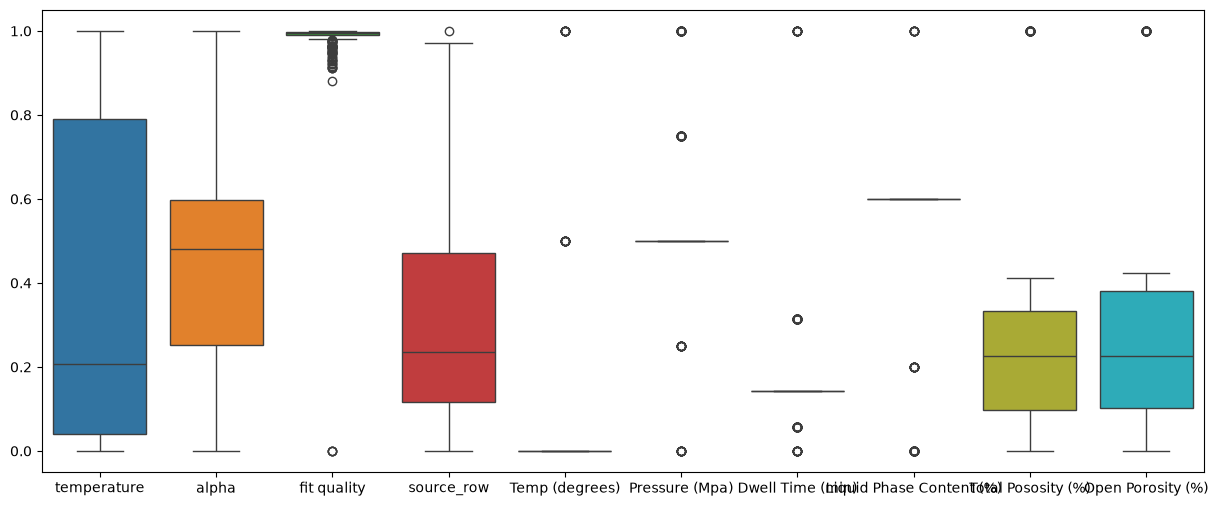

In [349]:
feature_boxplots(quartz_data, normalize=True)
plt.show()

Normalised boxplots were sued to compare distributions of numeric features . Fit quality is concentrated close to maximum value, with small number of substantially low observations. Temperature and thermal diffusivity also contain observations at lower end.

In [350]:
measurements.nsmallest(8, "alpha")[
    ["specimen_id", "temperature", "alpha", "fit quality"]
]

,specimen_id,temperature,alpha,fit quality
138,S15,397.0,1.870000e-07,0.0
139,S15,397.0,1.870000e-07,0.0
93,S12,497.0,2.160000e-07,0.0
190,S1,397.0,3.640000e-07,0.0
141,S15,398.0,1.400000e-03,92.9
82,S12,405.0,1.500000e-03,92.8
86,S12,400.0,1.540000e-03,92.7
145,S15,502.0,1.560000e-03,96.7


Further inspection reveals that there are 4 rows with alpha values that are several order smaller than the rest of the observations. Thesr rows also had fit qualities correspinding to zero. This clear seperation suggests they may represent failed or invalid fits.

In [351]:
measurements.nsmallest(8, "temperature")[
    ["specimen_id", "temperature", "alpha", "fit quality"]
]

,specimen_id,temperature,alpha,fit quality
129,S15,0.0031,0.00310,99.3
4,S1,19.0000,0.01130,99.3
5,S1,19.0000,0.01110,99.6
6,S1,19.0000,0.01110,99.7
7,S1,19.0000,0.01110,99.5
24,S11,19.0000,0.00967,99.5
25,S11,19.0000,0.00958,99.3
26,S11,19.0000,0.00951,99.5


Inspectiion of smallest temperature shows that for one row, the temperature is signiciantly lower than next smallest value. The temperature has the same value as thermal diffusivity, indicating a possible input error during data collection.

## 1.4 Sources

The number of rows before and after merging is compared to check that rows have not been removed or added. The merge adds specimen-lvel infornation to each exisiting observation so the total number of rows should stay the same.

In [352]:
print("Rows before merge:", len(measurements))
print("Rows after merge:", len(quartz_data))

Rows before merge: 321
Rows after merge: 321


In [353]:
assert len(measurements) == len(quartz_data)

## 1.5 Data Dictionary

In [354]:
data_dictionary = pd.DataFrame({
    "variable": [
        "specimen_id",
        "name",
        "temperature",
        "alpha",
        "fit quality",
        "measurement_regime",
        "Temp",
        "Pressure",
        "Dwell Time",
        "Liquid Phase Content",
        "Total Pososity",
        "Open Porosity",
        "source_filename",
        "source_row"
    ],

    "definition": [
        "Unique specimen identifier",
        "Original measurement identifier",
        "Temperature at which thermal diffusivity was measured",
        "Measured thermal diffusivity",
        "Measurement fit-quality value",
        "Standard or high-temperature measurement regime",
        "Cold-sintering processing temperature",
        "Cold-sintering pressure",
        "Cold-sintering dwell time",
        "Liquid-phase content used during processing",
        "Total specimen porosity",
        "Open specimen porosity",
        "Original Excel source file",
        "Original row in the source file"
    ],

    "unit": [
        "-",
        "-",
        "°C",
        "cm s⁻²",   
        "%",
        "-",
        "°C",
        "MPa",
        "min",
        "vol. %",
        "%",
        "%",
        "-",
        "-"
    ]
})

data_dictionary

data_dictionary

,variable,definition,unit
0,specimen_id,Unique specimen identifier,-
1,name,Original measurement identifier,-
2,temperature,Temperature at which thermal diffusivity was m...,°C
3,alpha,Measured thermal diffusivity,cm s⁻²
4,fit quality,Measurement fit-quality value,%
5,measurement_regime,Standard or high-temperature measurement regime,-
6,Temp,Cold-sintering processing temperature,°C
7,Pressure,Cold-sintering pressure,MPa
8,Dwell Time,Cold-sintering dwell time,min
9,Liquid Phase Content,Liquid-phase content used during processing,vol. %


## 1.6 Quality and unusual values

A data quality log is created to document unexpected or unreliable observations identified. 

In [355]:
quality_log = pd.DataFrame(columns=[
    "specimen_id",
    "source_filename",
    "source_row",
    "issue",
    "action",
    "reason"
])

In [356]:
low_temp = quartz_data.nsmallest(1, "temperature").iloc[0]

quality_log.loc[len(quality_log)] = [
    low_temp["specimen_id"],
    low_temp["source_filename"],
    low_temp["source_row"],
    "Unusually low temperature",
    "Retained",
    "Potential data-entry issue; temperature and alpha have the same unusually low value"
]


In [357]:
zero_fit = quartz_data[quartz_data["fit quality"] == 0]

for _, row in zero_fit.iterrows():
    quality_log.loc[len(quality_log)] = [
        row["specimen_id"],
        row["source_filename"],
        row["source_row"],
        "Zero fit quality",
        "Retained",
        "Zero fit quality coincides with an unusually low alpha value"
    ]

Quality log records one observation at unusually low temperature and four observations with zero fit quality. Observations are retained but flagged for further investigation.

# 2. Puplication Comparison

Compares prepared dataset with results reported in publication. Porcessing condtions are compared with total porosity. Repeat thermal-diffusivity measurements are summarised by speciman and measuremen regime, and results are checked against published tables and figures. 

Each processing comparison used only five of the specimens assocated with that processing parameter. This isolates changes in temp, pressure, dwell time or liquid phase content and provides comparison with publication.

## 2.1 Temperature-porosity

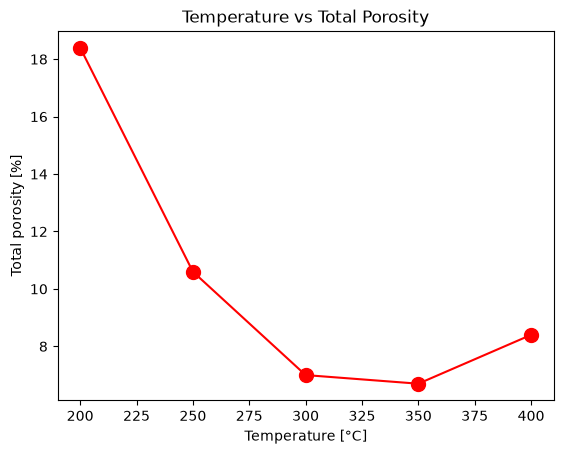

In [358]:
temperature_samples = sample_table_df[sample_table_df["Sample"].isin(["S1", "S2", "S3", "S4", "S5"])]

temperature_samples.sort_values("Temp (degrees)").plot(
    x="Temp (degrees)",
    y="Total Pososity (%)",
    color="red",
    marker="o",
    markersize=10,
    xlabel="Temperature [°C]",
    ylabel="Total porosity [%]",
    title="Temperature vs Total Porosity",
    legend=False
)

plt.show()

Initially increasing temperature increases the desnification. At the highest temperature, the densification decreases. The paper theroises that this decrease at a higher temperature could be due faster veaportation of liquid phase. This suggests that there could be a relationship between liquid phase content and temperature which is a otential feature to be explored before modelling.

## 2.2 Pressure-porosity

<Axes: title={'center': 'Pressure-porosity'}, xlabel='Pressure [MPa]', ylabel='Total porosity [%]'>

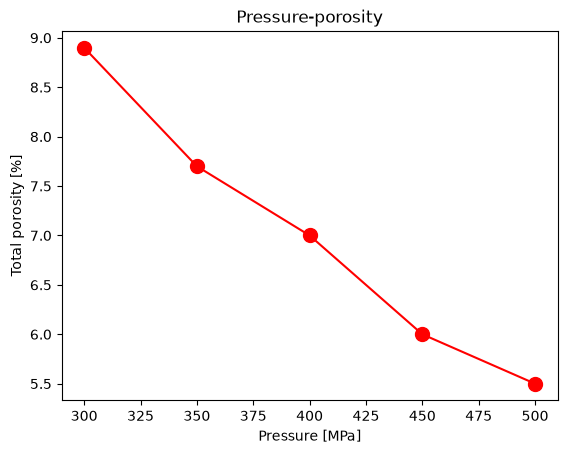

In [359]:
pressure_samples = sample_table_df[sample_table_df["Sample"].isin(["S1", "S6", "S7", "S8", "S9"])]

pressure_samples.sort_values("Pressure (Mpa)").plot(
    x="Pressure (Mpa)",
    y="Total Pososity (%)",
    color="red",
    marker="o",
    markersize=10,
    xlabel='Pressure [MPa]',
    ylabel='Total porosity [%]',
    title='Pressure-porosity',
    legend=False
)

The porosoity decreases approximately linearly, extrapolation would suggest that a Pressure of 800 MPa is required for complete densification. However, linearity is unrealistic due to effects in pore morphology and curvature. If a linear relationship is assumed with a natural log of pressure then densification required a pressure of approx 1100 MPa. log(pressure) could therefore be an insightful feature.

## 2.3 Dwell time-porosity


<Axes: title={'center': 'Dwell Time-porosity'}, xlabel='Dwell Time [min]', ylabel='Total porosity [%]'>

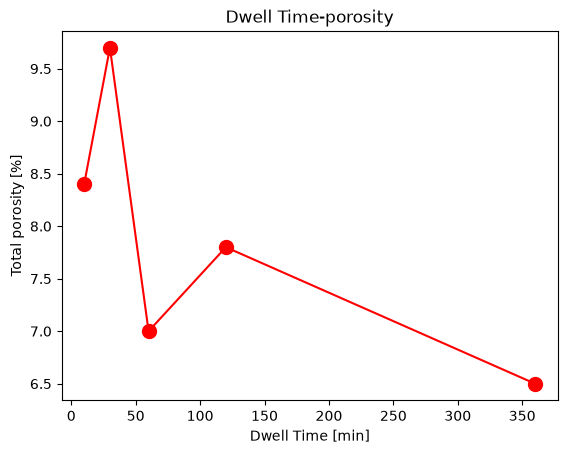

In [360]:
dwell_time_samples = sample_table_df[sample_table_df["Sample"].isin(["S1", "S10", "S11", "S12", "S13"])]

dwell_time_samples.sort_values("Dwell Time (min)").plot(
    x="Dwell Time (min)",
    y="Total Pososity (%)",
    color="red",
    marker="o",
    markersize=10,
    xlabel='Dwell Time [min]',
    ylabel='Total porosity [%]',
    title='Dwell Time-porosity',
    legend=False
)

## 2.4 Liquid phase-porosity

<Axes: title={'center': 'Liquid phase-porosity'}, xlabel='Liquid Phase Content [%]', ylabel='Total porosity [%]'>

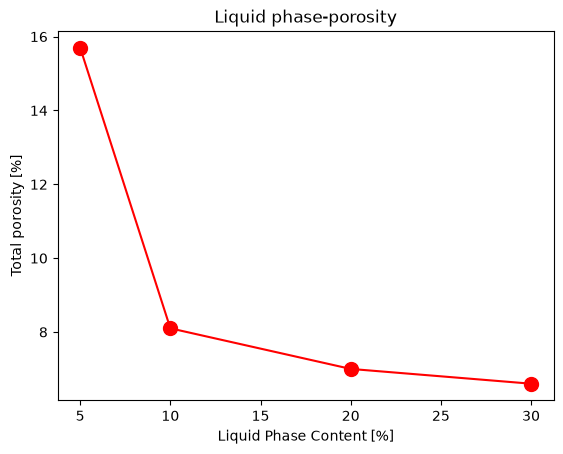

In [361]:
liquid_phase_samples = sample_table_df[sample_table_df["Sample"].isin(["S1", "S14", "S15", "S16", "S17"])]

liquid_phase_samples.sort_values("Liquid Phase Content (%)").plot(
    x="Liquid Phase Content (%)",
    y="Total Pososity (%)",
    color="red",
    marker="o",
    markersize=10,
    xlabel='Liquid Phase Content [%]',
    ylabel='Total porosity [%]',
    title='Liquid phase-porosity',
    legend=False
)

There is a clear relationship between densification and liquid phase content, althoug it appears the porosity because to trend towards a plateau so increasing liquid phase content is only beneficial up to a certain point.

Recreated processing-porosity plots closely match trends show in Figure 3 of paper, as expected because plots were generated using the processing and porosity values from table 2. Agreement provides useful check that specimen information was created correctly and that appropriate five-specimen series was selected for each processing parameter. Comparisons with fig 3 are approx visual checks.

## 2.5 Repeat measurements by specimen

Repeat thermal-diffusivity measurements are summarised for each specimen to assess number of measurements and their variability. Standard and high temperature measurements considered differently as they represent different measurement regimes.

In [362]:
repeat_summary = (
    quartz_data
    .groupby(["specimen_id", "measurement regime"])["alpha"]
    .agg(
        count="count",
        mean="mean",
        std="std",
        min="min",
        max="max"
    )
    .reset_index()
)

repeat_summary

,specimen_id,measurement regime,count,mean,std,min,max
0,S1,standard,38,0.005507,0.003370,3.640000e-07,0.01130
1,S10,standard,12,0.008698,0.000103,8.430000e-03,0.00885
2,S11,standard,36,0.005297,0.002686,2.610000e-03,0.00976
3,S12,standard,43,0.003971,0.002417,2.160000e-07,0.00887
4,S13,standard,12,0.007350,0.000085,7.110000e-03,0.00742
5,S15,standard,41,0.003184,0.001775,1.870000e-07,0.00605
6,S16,standard,12,0.007187,0.000045,7.090000e-03,0.00725
7,S17,standard,8,0.009084,0.000099,8.960000e-03,0.00925
8,S4,standard,12,0.006201,0.000231,5.520000e-03,0.00641
9,S5,standard,11,0.012218,0.000098,1.210000e-02,0.01240


In [363]:
# Coefficient of variation
repeat_summary["cv_percent"] = (
    repeat_summary["std"]
    / repeat_summary["mean"]
    * 100
)

repeat_summary

,specimen_id,measurement regime,count,mean,std,min,max,cv_percent
0,S1,standard,38,0.005507,0.003370,3.640000e-07,0.01130,61.193849
1,S10,standard,12,0.008698,0.000103,8.430000e-03,0.00885,1.188529
2,S11,standard,36,0.005297,0.002686,2.610000e-03,0.00976,50.711261
3,S12,standard,43,0.003971,0.002417,2.160000e-07,0.00887,60.871950
4,S13,standard,12,0.007350,0.000085,7.110000e-03,0.00742,1.161725
5,S15,standard,41,0.003184,0.001775,1.870000e-07,0.00605,55.730391
6,S16,standard,12,0.007187,0.000045,7.090000e-03,0.00725,0.619731
7,S17,standard,8,0.009084,0.000099,8.960000e-03,0.00925,1.086521
8,S4,standard,12,0.006201,0.000231,5.520000e-03,0.00641,3.724419
9,S5,standard,11,0.012218,0.000098,1.210000e-02,0.01240,0.803434


High-temperature regimes show the largest variabilty and spread in thermal diffusivity. However, these measurements span a wider range of measurement temperatures, so variability is not poor repeatability. Observed spread is likely associated with change in thermal diffusivity with measurement temperature. Rpeatability of high-temp data should be assessed by comparing measurments taken at similar temperatures.

Processing-porosity plots reproduce th trends in fig 3, wth each comparison containing only the five specimens used to vary relevant processing conditions. PLotted trends closely resembly those in pubilication, as expected because values were taken from table 2. Plots therefore provide approx visual comparisonwith fig 3.

Specimen level procressing conditions and porosity values were also checked against table 2. Represents exact table check. Misiing values were retained as NaN where specimen has fractured or no valid result was avaialble.

Repeat measurement summary shows that the measurement variability differs between specimens and measurement regimes. The high temp measurements generally have a greater spread than standard. This variability should be considered when comparing experimental measurements. Flagged results, were retained and documented in log rather than automatically removed.

## 2.6 Thermal Conductivity

Thermal conductivity calculated using thermal diffusivity, bulk density, and temperature dependent specific heat capacity.

(specific heat constants from Kotrbova et al. for loq-quartz below 573 degrees celsius)

(bulk density eq. dervied from 'Bulk density and particle density, water content)

(specific heat eq. from published paper)


In [364]:
def specific_heat(temp_c):
    """
    Calculates low-quartz specific heat using eq.17 from [26]

    Parameters:
    temp_c: float of prandas Series
        Measurement temp in celsius

    Returns:
    sc: float or pandas Series
        Specific heat capacity in J(kg K)
    """
    temp_k = temp_c + 273.15

    cp = (0.7310 + 0.6460e-3 * temp_k - 0.1608e5 / temp_k**2) * 1000

    return cp

quartz_data["specific_heat"] = specific_heat(quartz_data["temperature"])

In [365]:
def bulk_density(th_density, porosity):
    """
    Calculates bulk density from theoretical density and total porosity

    Parameters: 

    th_density:float
        Theoretical density in kg/m^3
    porosity: float or pandas Series
        Total porosity as percentage

    Returns:

    float or pandas Series
        Bulk density in kg/m^3
    """
    return th_density * (1 - (porosity/100))

quartz_data["density_kg_m3"] = bulk_density(
    th_density=2650,
    porosity=quartz_data["Total Pososity (%)"]
)

In [366]:
def thermal_cond (alpha, density, cp):
    """
    Calculates thermal conductivity.

    Paremeters:
     alpha:float or pandas Seres
        Thermal diffusivity
    density: float or pandas Series
        Bulk desnity in kg/m^3
    cp: float or pandas Series
        Specific heat in J/kg K

    Returns: float or pandas Series
        Thermal conductivity
    """
    return alpha * density * cp

quartz_data["alpha_m2_s"] = quartz_data["alpha"] * 1e-4

quartz_data["conductivity_W_mK"] = thermal_cond(
    alpha=quartz_data["alpha_m2_s"],
    density=quartz_data["density_kg_m3"],
    cp=quartz_data["specific_heat"]
)

In [367]:
paper_thermal_cond= {
    'S1': 2.02,
    'S4': 1.14,
    'S5': 2.16,
    'S6': 1.30,
    'S7': 1.45, 
    'S8': 1.36,
    'S9': 1.78,
    'S10': 1.56,
    'S11': 1.68,
    'S12': 1.41,
    'S13': 1.34,
    'S15': 0.98,
    'S16': 1.29,
    'S17': 1.66
}

In [368]:
conductivity_table = (
    quartz_data.loc[(quartz_data["temperature"] - 20).abs() <= 0.5]
    .groupby("specimen_id", as_index=False)["conductivity_W_mK"]
    .mean()
)

conductivity_table["paper_W_mK"] = (
    conductivity_table["specimen_id"].map(paper_thermal_cond)
)

display(conductivity_table.style.format({
    "conductivity_W_mK": "{:.2f}",
    "paper_W_mK": "{:.2f}"
}))

,specimen_id,conductivity_W_mK,paper_W_mK
0,S1,2.01,2.02
1,S10,1.56,1.56
2,S11,1.70,1.68
3,S12,1.42,1.41
4,S13,1.34,1.34
5,S15,0.98,0.98
6,S16,1.28,1.29
7,S17,1.65,1.66
8,S4,1.14,1.14
9,S5,2.17,2.16


Calculated conductivity values were averaged by specimen for measurements within ±0.5°C of 20°C and comapred with values from table 3. The values agree closely with the values from the paper. At two dp, S10, S13, S15 and S4 match the published values, whilst most other specimens differ by only 0.01. Largest difference is S9. 

Small differences may reflect rounding of published porosoity values used to reconstruct density, differences in averging repeat measurements, or spefici heat calculation. Individual contributions cannot be confirmed from available information.

# 3. EDA

## 3.1 Measurement Distributions

Histograms used to examine distributions, reflect both temperature variation and unuequal number of repeats between speicmens.

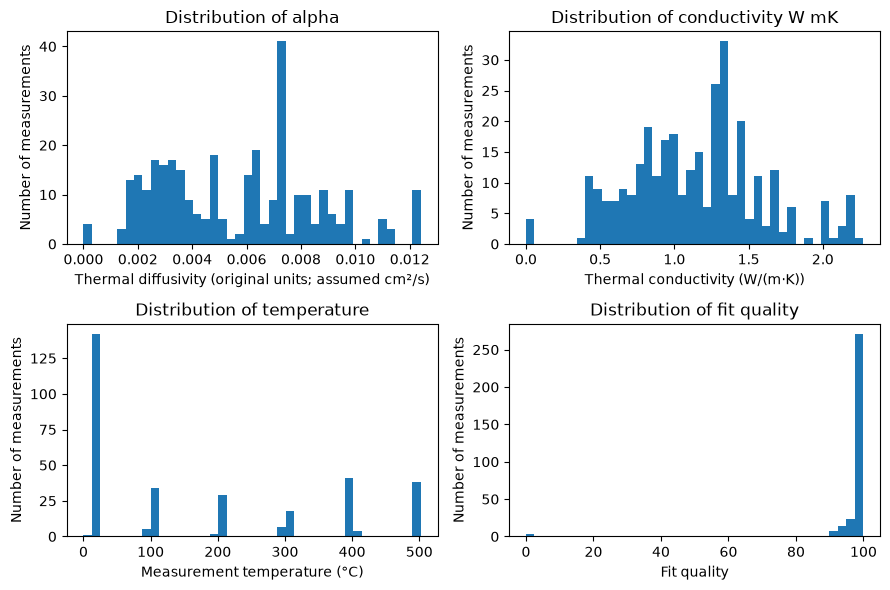

In [369]:
columns = ["alpha","conductivity_W_mK","temperature","fit quality"]

labels = [
    "Thermal diffusivity (original units; assumed cm²/s)",
    "Thermal conductivity (W/(m·K))",
    "Measurement temperature (°C)",
    "Fit quality"
]

fig, axes = plt.subplots(2, 2, figsize=(9, 6))

for ax, column, label in zip(axes.flat, columns, labels):
    ax.hist(quartz_data[column].dropna(), bins=40)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of measurements")
    ax.set_title(f"Distribution of {column.replace('_', ' ')}")

plt.tight_layout()
plt.show()

Distribtions combine different specimens, temperatures and repeat counts, so any spread or clustering is not soley due to differences between specimens. Diffusivity and conductivity show multiple peaks rather than single symmetric distribution. Patterns combine differences between specimens, temperatures and repeat counts. Measurements are concentrated at discrete temperatures, with largest near room temperature. Most fit quality values are close to 100, while a small number are zero, these values were flagged earlier.

Room temp thermal conductivity plotted seperately to compare measurements under similar conditions, consistent with publications condtions. Removes variation associated with combined measurement temperatures.

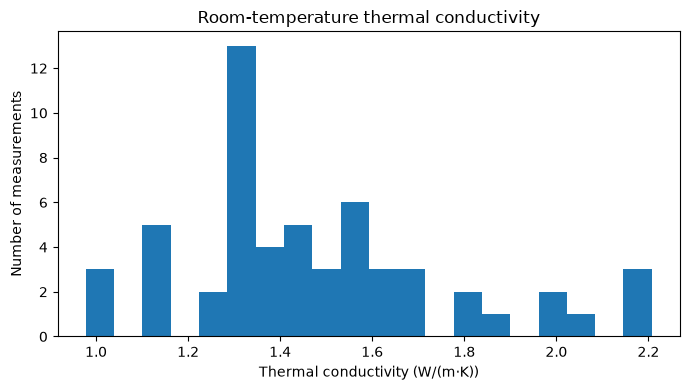

In [370]:
room_temp = quartz_data.loc[(quartz_data["temperature"] - 20).abs() <= 0.5]

fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(room_temp["conductivity_W_mK"].dropna(), bins=20)
ax.set_xlabel("Thermal conductivity (W/(m·K))")
ax.set_ylabel("Number of measurements")
ax.set_title("Room-temperature thermal conductivity")

plt.tight_layout()
plt.show()

Seperating these measurements removes variation with different temperature measurements. However, plot still shows different specimens, amd specimens with more repeats contribute more observations.

## 3.2 Repeat Measurement Variability

Seperating the variations within samples from differences between samples.

In [371]:
room_temp = quartz_data.loc[(quartz_data["temperature"] - 20).abs() <= 0.5].copy()

repeat_summary = (
    room_temp.groupby("specimen_id")["conductivity_W_mK"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
)

display(repeat_summary.round(3))

,specimen_id,count,mean,std,min,max
0,S1,3,2.012,0.028,1.988,2.042
1,S10,6,1.555,0.011,1.543,1.575
2,S11,3,1.697,0.013,1.688,1.713
3,S12,3,1.419,0.008,1.410,1.424
4,S13,7,1.342,0.004,1.337,1.348
5,S15,3,0.978,0.001,0.978,0.980
6,S16,6,1.284,0.009,1.266,1.293
7,S17,3,1.652,0.001,1.652,1.653
8,S4,5,1.141,0.005,1.137,1.148
9,S5,3,2.171,0.031,2.154,2.207


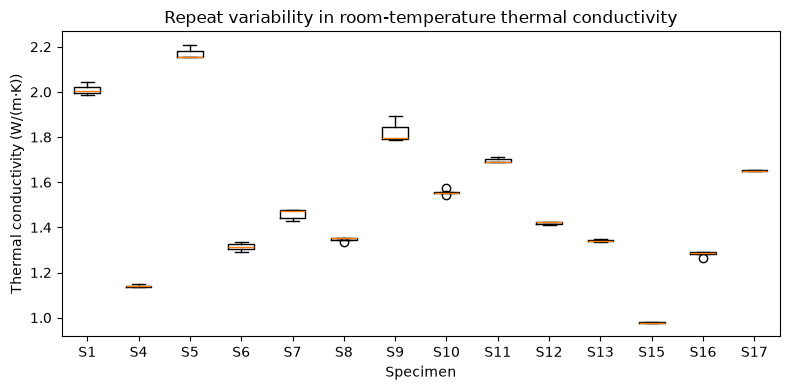

In [372]:
# Put specimens in numerical order
specimen_order = sorted(
    room_temp["specimen_id"].dropna().unique(),
    key=lambda sample: int(sample.replace("S", ""))
)

data = [
    room_temp.loc[
        room_temp["specimen_id"] == specimen,
        "conductivity_W_mK"
    ].dropna()
    for specimen in specimen_order
]

fig, ax = plt.subplots(figsize=(8, 4))

ax.boxplot(data)
ax.set_xticks(range(1, len(specimen_order) + 1))
ax.set_xticklabels(specimen_order)
ax.set_xlabel("Specimen")
ax.set_ylabel("Thermal conductivity (W/(m·K))")
ax.set_title("Repeat variability in room-temperature thermal conductivity")

plt.tight_layout()
plt.show()

Room temp conductivity shows generally low variability within each soecimen, compared to differences between specimens.

## 3.3 Effect of measurement temperature

Conductivity plotted against measurement temperature for each specimen to explore behaviour. Repeat measurements are averaged at each recorded temperature. Measurment temp is distinct from sintering temp used during preperation.

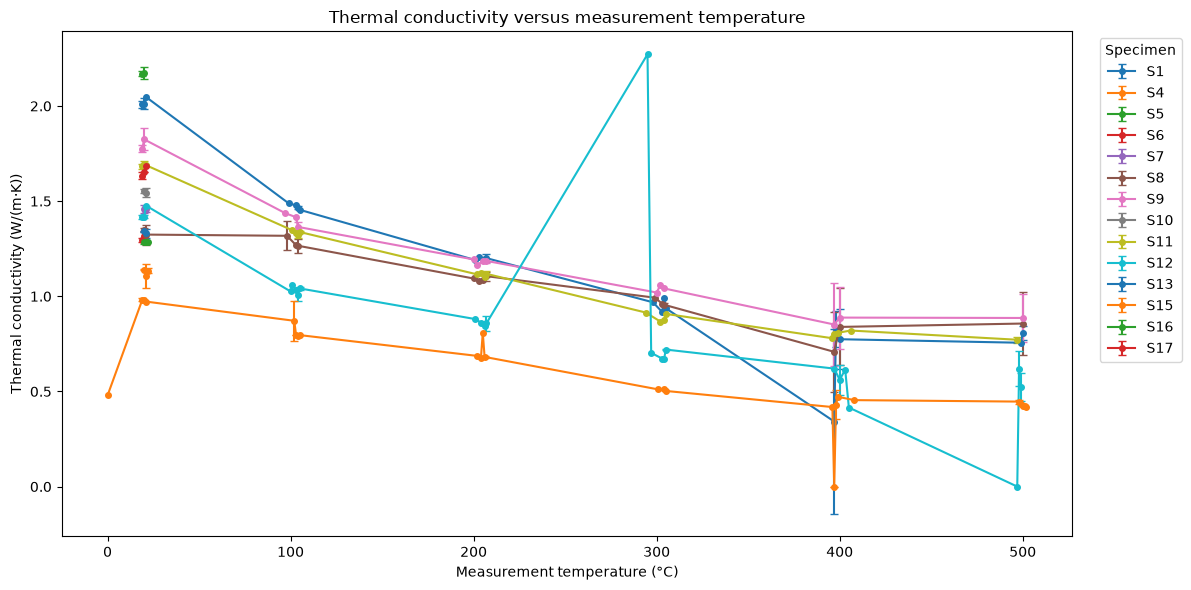

In [373]:
temperature_summary = (
    quartz_data.groupby(["specimen_id", "temperature"])["conductivity_W_mK"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

specimen_order = sorted(
    temperature_summary["specimen_id"].unique(),
    key=lambda sample: int(sample.replace("S", ""))
)

fig, ax = plt.subplots(figsize=(12, 6))

for specimen in specimen_order:
    data = (
        temperature_summary.loc[
            temperature_summary["specimen_id"] == specimen
        ].sort_values("temperature")
    )

    ax.errorbar(data["temperature"],data["mean"],yerr=data["std"],marker="o",markersize=4,capsize=3,label=specimen)

ax.set_xlabel("Measurement temperature (°C)")
ax.set_ylabel("Thermal conductivity (W/(m·K))")
ax.set_title("Thermal conductivity versus measurement temperature")
ax.legend(title="Specimen", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Thermal conductivity generally decreases with increasing measurement temperature for most specimens. However, there are several unusual high-temp values. These should be investigated alongisde measurement information before temperature deondence is investigated further.

In quartz structure, heat is mainly carried by lattice vibrations. As temperature changes, the way phonons travel and scatter changes, so thermal conductivity shows a temperature dependence. The paper concludes the possible presence of an amorphous phase and crystallographic defects. These irregularites scatter phonons regardless of temperature. This can make thermal conductivity change less temperature, which could explain the weak dependence seen.

In [374]:
quartz_data.loc[
    quartz_data["fit quality"] == 0,
    [
        "specimen_id",
        "temperature",
        "alpha",
        "fit quality",
        "conductivity_W_mK"
    ]
]

,specimen_id,temperature,alpha,fit quality,conductivity_W_mK
93,S12,497.0,2.160000e-07,0.0,0.000063
138,S15,397.0,1.870000e-07,0.0,0.000047
139,S15,397.0,1.870000e-07,0.0,0.000047
190,S1,397.0,3.640000e-07,0.0,0.000101


Sveral near-zero conductivity values at high temperatures correspond to measurements with fit qualities of zero. Thesse contain unusually low diffusivity values which influnce the calulcated conductivity values,

A high conductivty value is observed at 295 degrees. Analysis shows thisis casued by a thermal diffsusivity approx three times higher than neighbouring measurements.

In [375]:
issue = 'Unusually high thermal diffusivity at 295 degrees'

measurement = quartz_data.loc[
    (quartz_data["specimen_id"] == "S12") &
    (quartz_data["temperature"] == 295)
].iloc[0]

if not (
    (quality_log["specimen_id"] == "S12") &
    (quality_log["issue"] == issue)
).any():
    quality_log.loc[len(quality_log)] = [
        measurement["specimen_id"],
        measurement["source_filename"],
        measurement["source_row"],
        issue,
        "Flagged",
        "Alpha = 0.00887, approximately three times higher than surrounding S12 measurements",
    ]

display(quality_log)

,specimen_id,source_filename,source_row,issue,action,reason
0,S15,Temperature_data_(thermal_diffusivity)_sample_...,11,Unusually low temperature,Retained,Potential data-entry issue; temperature and al...
1,S12,Temperature_data_(thermal_diffusivity)_sample_...,30,Zero fit quality,Retained,Zero fit quality coincides with an unusually l...
2,S15,Temperature_data_(thermal_diffusivity)_sample_...,20,Zero fit quality,Retained,Zero fit quality coincides with an unusually l...
3,S15,Temperature_data_(thermal_diffusivity)_sample_...,21,Zero fit quality,Retained,Zero fit quality coincides with an unusually l...
4,S1,Temperature_data_(thermal_diffusivity)_sample_...,19,Zero fit quality,Retained,Zero fit quality coincides with an unusually l...
5,S12,Temperature_data_(thermal_diffusivity)_sample_...,13,Unusually high thermal diffusivity at 295 degrees,Flagged,"Alpha = 0.00887, approximately three times hig..."


## 3.4 EDA Dataframe

Creating a dataframe copy without flagged issues to assess their influence on observed temperature trends

In [376]:
eda_measurements = quartz_data.loc[
    (quartz_data["fit quality"] != 0) &
    ~(
        (quartz_data["specimen_id"] == "S12") &
        (quartz_data["temperature"] == 295)
    )
].copy()

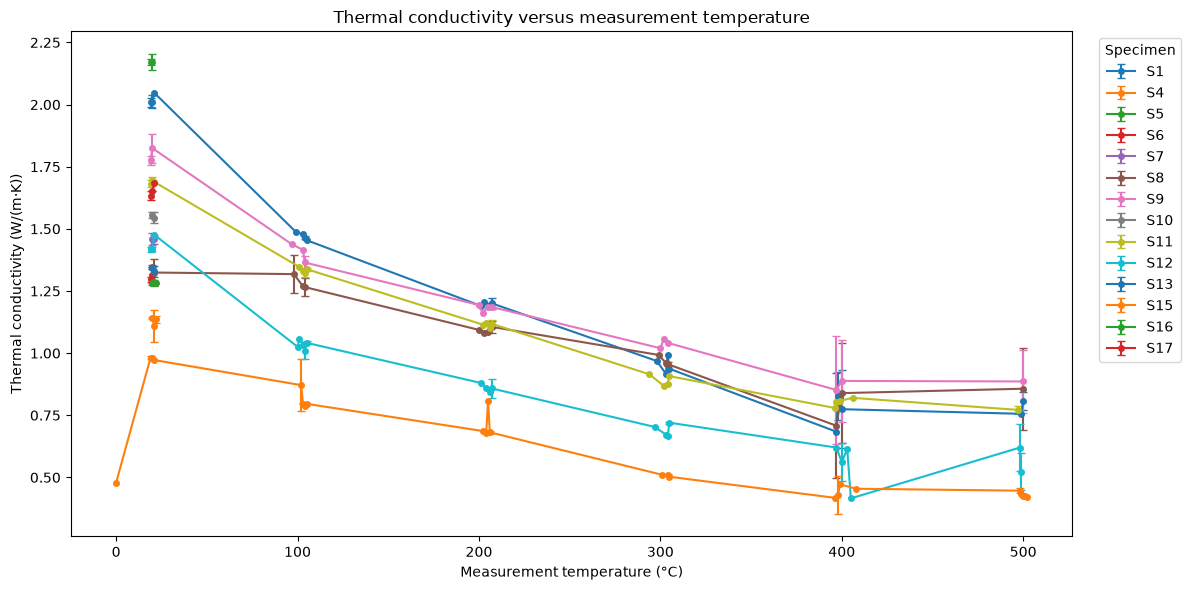

In [377]:
temperature_summary = (
    eda_measurements.groupby(["specimen_id", "temperature"])["conductivity_W_mK"]
    .agg(["count", "mean", "std"])
    .reset_index()
)

specimen_order = sorted(
    temperature_summary["specimen_id"].unique(),
    key=lambda sample: int(sample.replace("S", ""))
)

fig, ax = plt.subplots(figsize=(12, 6))

for specimen in specimen_order:
    data = (
        temperature_summary.loc[
            temperature_summary["specimen_id"] == specimen
        ].sort_values("temperature")
    )

    ax.errorbar(data["temperature"],data["mean"],yerr=data["std"],marker="o",markersize=4,capsize=3,label=specimen)

ax.set_xlabel("Measurement temperature (°C)")
ax.set_ylabel("Thermal conductivity (W/(m·K))")
ax.set_title("Thermal conductivity versus measurement temperature")
ax.legend(title="Specimen", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [378]:
display(
    quartz_data.loc[
        (quartz_data["specimen_id"] == "S15") &
        (quartz_data["temperature"] < 10),
        [
            "name",
            "specimen_id",
            "temperature",
            "alpha",
            "fit quality",
            "specific_heat",
            "conductivity_W_mK"
        ]
    ]
)

,name,specimen_id,temperature,alpha,fit quality,specific_heat,conductivity_W_mK
129,CSP SiO2 HT1_1_11,S15,0.0031,0.0031,99.3,691.943751,0.479188


In [379]:
issue = "Suspicious temperature value of 0.0031°C"

measurement = quartz_data.loc[
    (quartz_data["specimen_id"] == "S15") &
    (quartz_data["name"] == "CSP SiO2 HT1_1_11")
].iloc[0]

if not (
    (quality_log["specimen_id"] == "S15") &
    (quality_log["issue"] == issue)
).any():
    quality_log.loc[len(quality_log)] = [
        measurement["specimen_id"],
        measurement["source_filename"],
        measurement["source_row"],
        issue,
        "Flagged",
        "Temperature equals alpha (0.0031); surrounding HT measurements are approximately 200°C",
    ]


In [380]:
keys = ["source_filename", "source_row"]

flagged = quality_log.loc[
    quality_log["action"] == "Flagged", keys
].dropna()

is_flagged = pd.MultiIndex.from_frame(quartz_data[keys]).isin(
    pd.MultiIndex.from_frame(flagged)
)

eda_measurements = quartz_data.loc[
    (quartz_data["fit quality"] != 0) & ~is_flagged
].copy()

## 3.5 Processing-strcture-property relationships

Relationship between conductivity and porosity examined to determine how material strcuture relates to thermal transport. Creating similr to plot to fig 9 in publication.

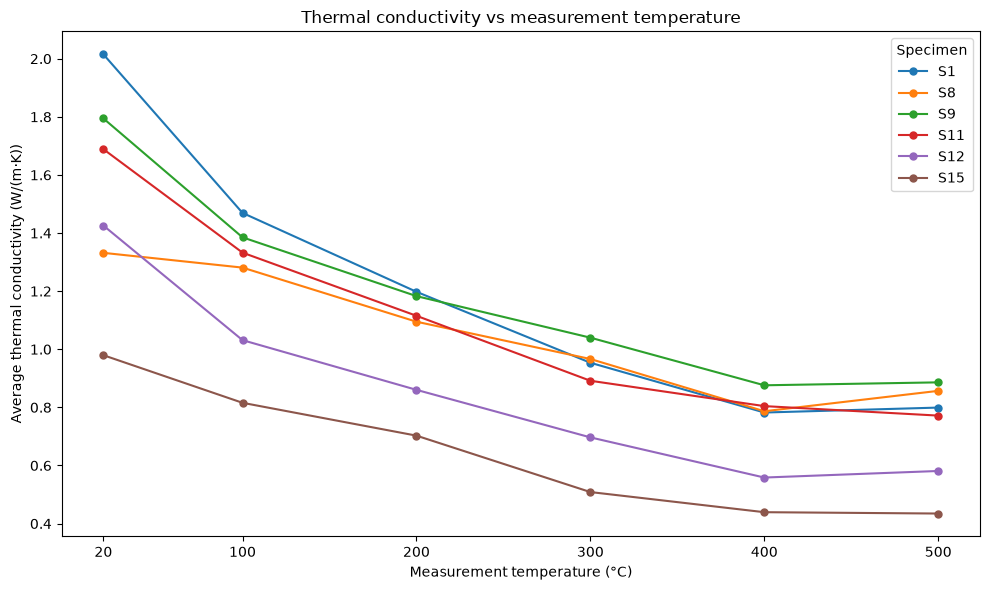

In [381]:
samples_to_plot = ["S1", "S8", "S9", "S11", "S12", "S15"]

# Create copy for plotting
plot_data = eda_measurements[
    eda_measurements["specimen_id"].isin(samples_to_plot)
].copy()

# Group measurements into the six nominal temperatures
plot_data["temp_group"] = (
    plot_data["temperature"] / 100
).round() * 100

# Keep the six temperature groups
plot_data = plot_data[plot_data["temp_group"].isin([0, 100, 200, 300, 400, 500])]

# Treat the room-temperature group as 20°C
plot_data.loc[plot_data["temp_group"] == 0,"temp_group"] = 20

# Calculate one average conductivity per specimen at each temperature
plot_summary = (plot_data.groupby( ["specimen_id", "temp_group"],as_index=False)["conductivity_W_mK"].mean())

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

for specimen in samples_to_plot:
    data = (
        plot_summary[
            plot_summary["specimen_id"] == specimen
        ]
        .sort_values("temp_group")
    )

    ax.plot(data["temp_group"],data["conductivity_W_mK"],marker="o",markersize=5,label=specimen)

ax.set_xlabel("Measurement temperature (°C)")
ax.set_ylabel("Average thermal conductivity (W/(m·K))")
ax.set_title("Thermal conductivity vs measurement temperature")

ax.set_xticks([20, 100, 200, 300, 400, 500])

ax.legend(title="Specimen")

plt.tight_layout()
plt.show()

Thermal conductivity generally decreases with increasing measurement temperature across specimens, with the largest decrease occurring at lower measurement temperatures. At higher temperatures, conductivity tends to level off.

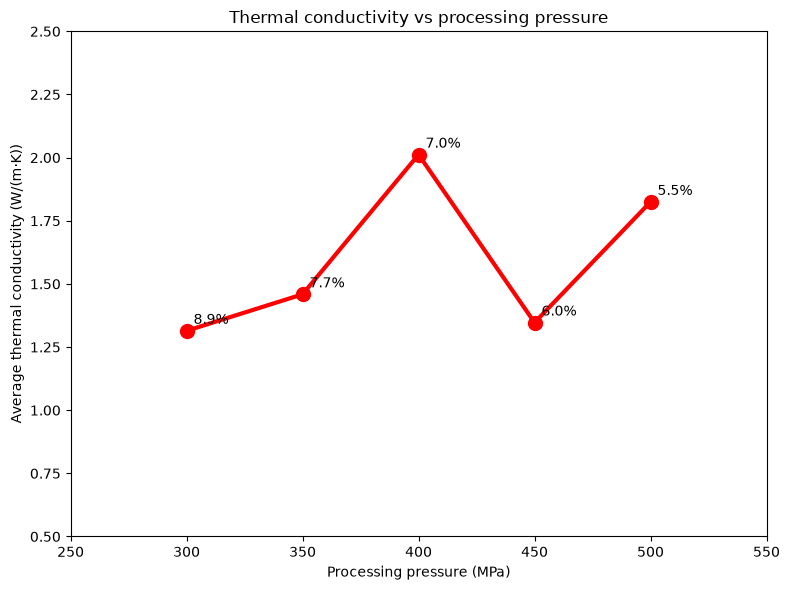

In [382]:
samples_to_plot = ["S1", "S6", "S7", "S8", "S9"]

# Calculate average room-temperature conductivity for each specimen
plot_summary = (
    eda_measurements[
        (eda_measurements["specimen_id"].isin(samples_to_plot)) &
        ((eda_measurements["temperature"] - 20).abs() <= 0.5)
    ]
    .groupby("specimen_id", as_index=False)["conductivity_W_mK"]
    .mean()
)

# Add processing pressure
plot_summary = plot_summary.merge(
    sample_table_df[["Sample", "Pressure (Mpa)", 'Total Pososity (%)']],
    left_on="specimen_id",
    right_on ='Sample',
    how="left",
    validate='many_to_one'
)

# Sort by pressure
plot_summary = plot_summary.sort_values("Pressure (Mpa)")

# Plot
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    plot_summary["Pressure (Mpa)"],
    plot_summary["conductivity_W_mK"],
    marker="o",
    markersize=10, 
    color = 'r', 
    linewidth = 3
)

# Label points
for _, row in plot_summary.iterrows():
    ax.annotate(
        f'{row["Total Pososity (%)"]:.1f}%',
        (row["Pressure (Mpa)"], row["conductivity_W_mK"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlabel("Processing pressure (MPa)")
ax.set_ylabel("Average thermal conductivity (W/(m·K))")
ax.set_title("Thermal conductivity vs processing pressure")
ax.set_xlim(250, 550)
ax.set_ylim(0.5, 2.5)

plt.tight_layout()
plt.show()

There appears to be no obvious relationship between pressure at thermal conductivity. This suggests that processing pressure may not fully explain the variation in thermal conductivity and that other characteristics should also be consirdered.

# 4. Features

As mentioned in 2.1 and 2.2, some engineered features could prove more insightful when modelling.

In [383]:
eda_measurements['log_pressure'] = np.log10(eda_measurements['Pressure (Mpa)'])

In [384]:
eda_measurements['temp_liquid_interaction'] = eda_measurements['Liquid Phase Content (%)'] * eda_measurements['temperature']

# 5. Models

## 5.1 Prediction

Thermal conductivity can be predicted for unseen specimen using measurement temperature and specimens processing/material characteristics.

In [385]:
target_col = "conductivity_W_mK"
group_col = "specimen_id"

original_features = [
    "temperature",
    "Total Pososity (%)",
    "Pressure (Mpa)",
    "Temp (degrees)",
    "Dwell Time (min)",
    "Liquid Phase Content (%)"
]

In [386]:
feature_sets = {
    "Ridge: original features": original_features,

    "Ridge: log pressure": [
        "temperature",
        "Total Pososity (%)",
        "log_pressure",
        "Temp (degrees)",
        "Dwell Time (min)",
        "Liquid Phase Content (%)"
    ],

    "Ridge: interaction feature": original_features + [
        "temp_liquid_interaction"
    ],

    "Ridge: all engineered features": [
        "temperature",
        "Total Pososity (%)",
        "log_pressure",
        "Temp (degrees)",
        "Dwell Time (min)",
        "Liquid Phase Content (%)",
        "temp_liquid_interaction"
    ]
}

In [387]:
all_features = sorted({
    feature
    for features in feature_sets.values()
    for feature in features
})

In [389]:
model_df = eda_measurements.copy()

dev_set, test_set = split_by_group(
    df=model_df,
    required_cols=all_features + [target_col],
    group_col=group_col,
    test_size=0.20,
    random_state=42
)

In [390]:
print("Development specimens:")
print(sorted(dev_set[group_col].unique()))

print("\nTest specimens:")
print(sorted(test_set[group_col].unique()))

print(
    "\nNumber of development specimens:",
    dev_set[group_col].nunique()
)

print(
    "Number of test specimens:",
    test_set[group_col].nunique()
)

assert set(dev_set[group_col]).isdisjoint(
    set(test_set[group_col])
)

Development specimens:
['S10', 'S11', 'S12', 'S13', 'S15', 'S16', 'S17', 'S4', 'S6', 'S8', 'S9']

Test specimens:
['S1', 'S5', 'S7']

Number of development specimens: 11
Number of test specimens: 3


In [391]:
comparison, validation_predictions = compare_feature_sets(
    dev_set=dev_set,
    feature_sets=feature_sets,
    target_col=target_col,
    group_col=group_col,
    alpha=1.0
)

display(comparison)

,Model,MAE [W/mK],RMSE [W/mK]
0,Training-mean baseline,0.324796,0.386031
1,Ridge: original features,0.223618,0.292818
2,Ridge: log pressure,0.213795,0.280417
3,Ridge: interaction feature,0.254717,0.327067
4,Ridge: all engineered features,0.244266,0.309837


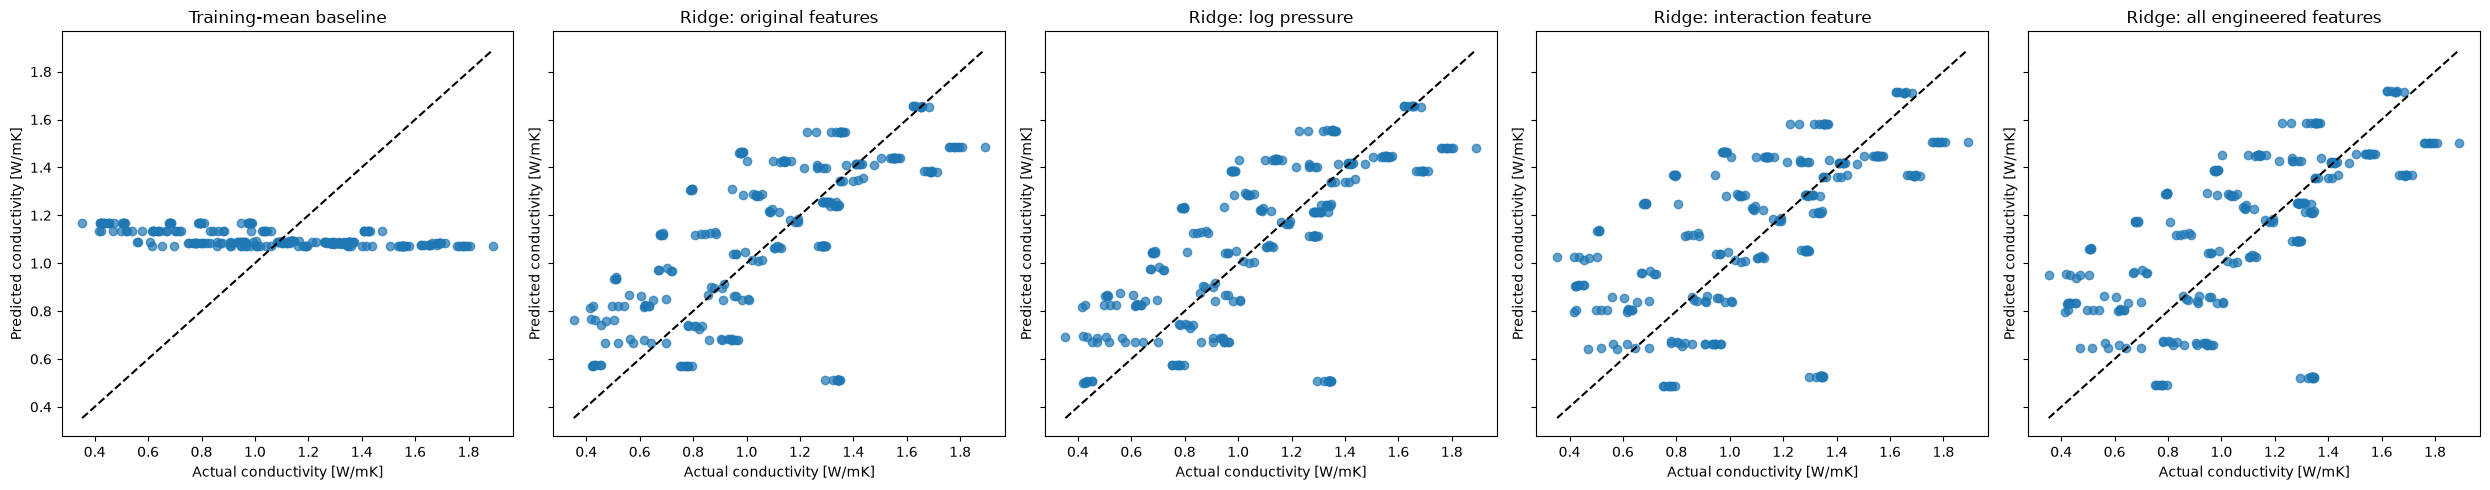

In [392]:
y_dev = dev_set[target_col]

all_values = np.concatenate([
    y_dev.to_numpy(),
    *validation_predictions.values()
])

min_val = all_values.min()
max_val = all_values.max()

n_models = len(validation_predictions)

fig, axes = plt.subplots(
    1,
    n_models,
    figsize=(5 * n_models, 5),
    sharex=True,
    sharey=True
)

if n_models == 1:
    axes = [axes]

for ax, (model_name, predictions) in zip(
    axes,
    validation_predictions.items()
):
    ax.scatter(
        y_dev,
        predictions,
        alpha=0.7
    )

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="black",
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Actual conductivity [W/mK]")
    ax.set_ylabel("Predicted conductivity [W/mK]")

plt.tight_layout()
plt.show()

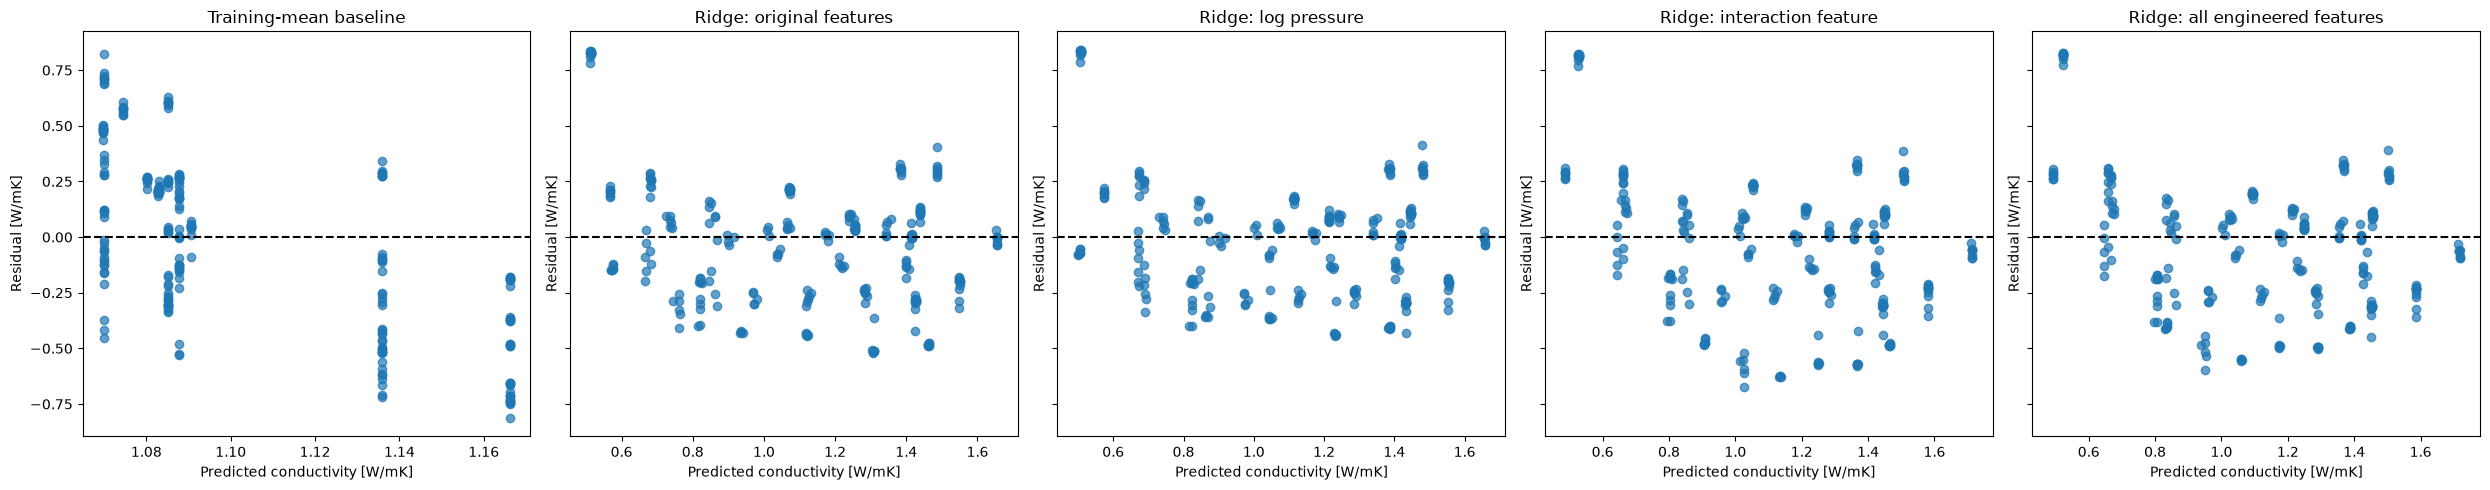

In [394]:
n_models = len(validation_predictions)

fig, axes = plt.subplots(
    1,
    n_models,
    figsize=(5 * n_models, 5),
    sharey=True
)

if n_models == 1:
    axes = [axes]

for ax, (model_name, predictions) in zip(
    axes,
    validation_predictions.items()
):
    residuals = y_dev.to_numpy() - predictions

    ax.scatter(
        predictions,
        residuals,
        alpha=0.7
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted conductivity [W/mK]")
    ax.set_ylabel("Residual [W/mK]")

plt.tight_layout()
plt.show()

In [396]:
# Select the Ridge model with the lowest validation MAE
ridge_results = comparison[
    comparison["Model"].isin(feature_sets.keys())
]

best_row = ridge_results.loc[
    ridge_results["MAE [W/mK]"].idxmin()
]

selected_model_name = best_row["Model"]
selected_features = feature_sets[selected_model_name]

print("Selected model:", selected_model_name)
print("Selected features:", selected_features)
print(f'Validation MAE: {best_row["MAE [W/mK]"]:.3f} W/mK')
print(f'Validation RMSE: {best_row["RMSE [W/mK]"]:.3f} W/mK')

Selected model: Ridge: log pressure
Selected features: ['temperature', 'Total Pososity (%)', 'log_pressure', 'Temp (degrees)', 'Dwell Time (min)', 'Liquid Phase Content (%)']
Validation MAE: 0.214 W/mK
Validation RMSE: 0.280 W/mK


All ridge models show substantial improvement over mean-baseline, with predictions following the observed variation in thermal condcuctivity. Baseline produces approx constant so shows strong systematic pattern in residuals.

Rudge models are more closely centered around zero, although clustering and some relatively large prediction errors remain. Original and engineered features show broadly similar behaviour visually, so model swlwction is based on grouped MAE.

Relatively small number of independent specimens should be considered, since repeated measurements from same specimen share several specimen-lvel input features,

## 5.2 Test Data

In [398]:
# Create the selected Ridge model
final_model = make_ridge_model(alpha=1.0)

# Development data
X_dev = dev_set[selected_features]
y_dev = dev_set[target_col]

# Test data
X_test = test_set[selected_features]
y_test = test_set[target_col]

# Fit using all development specimens
final_model.fit(X_dev, y_dev)

# Predict the held-out test specimens
test_predictions = final_model.predict(X_test)

# Calculate test metrics
test_metrics = calculate_metrics(
    y_test,
    test_predictions
)

print("Selected model:", selected_model_name)
print(f'Test MAE: {test_metrics["MAE [W/mK]"]:.3f} W/mK')
print(f'Test RMSE: {test_metrics["RMSE [W/mK]"]:.3f} W/mK')

Selected model: Ridge: log pressure
Test MAE: 0.403 W/mK
Test RMSE: 0.626 W/mK


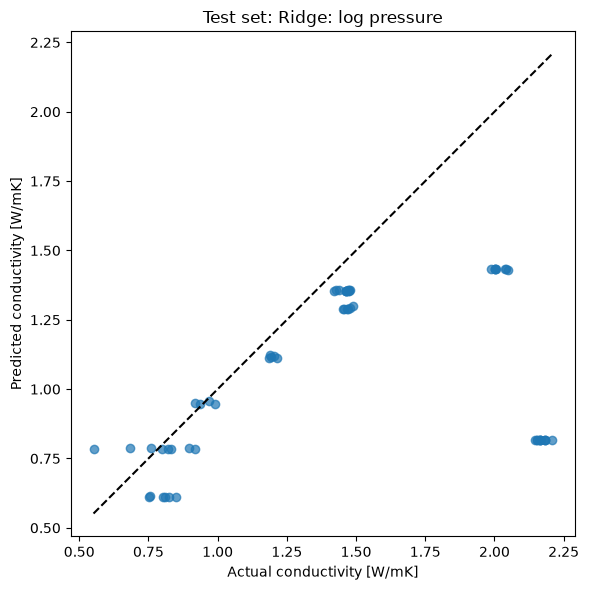

In [399]:
min_val = min(y_test.min(), test_predictions.min())
max_val = max(y_test.max(), test_predictions.max())

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    y_test,
    test_predictions,
    alpha=0.7
)

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    "k--"
)

ax.set_xlabel("Actual conductivity [W/mK]")
ax.set_ylabel("Predicted conductivity [W/mK]")
ax.set_title(f"Test set: {selected_model_name}")

plt.tight_layout()
plt.show()

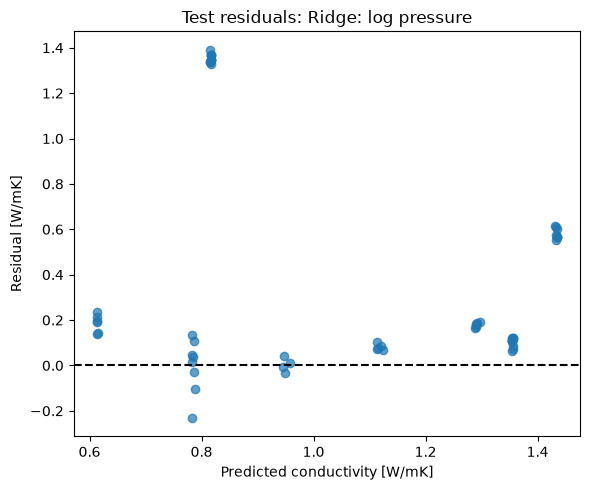

In [400]:
test_residuals = y_test.to_numpy() - test_predictions

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    test_predictions,
    test_residuals,
    alpha=0.7
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_xlabel("Predicted conductivity [W/mK]")
ax.set_ylabel("Residual [W/mK]")
ax.set_title(f"Test residuals: {selected_model_name}")

plt.tight_layout()
plt.show()

Risge regression model using log-transformed pressure was slected based on performance during grouped development validation. Predicted versus actual plot shows that model captures some of the variation in thermal conductivity, particularly at lower and intermediate values. However, several higher-conductivity observations are substantially underpredicted. This is also apparent in residual plot. 

Test performance is poorer than development performance, inidcating limited generalisation on unseen specimens, particularly three specimens in test set.